<img src="recursos/logo_UTN.svg" align="right" width="150" /> 

#### Teoría de Circuitos II

# Tarea Semanal 7

Docentes: *LLAMEDO SORIA, Mariano* y *MOHAROS, David*

Autor: *MARCHESI, Matías Sebastián*


## Introducción

En esta tarea se busca sintetizar una expresión inmitancia en impedancia y admitancia utilizando los métodos vistos en clase.

A su vez, partiendo de un circuito, se hará el mapa de remociones para hallar los valores de sus componentes.

## Desde Ecuación Inmitancia a Circuito

La siguiente inmitancia será resuelta de cuatro maneras diferentes para llegar a distintos circuitos.

$$F(s) = \frac{s^2 + 4s^2 + 3}{s(s^2 + 2)}$$

Comenzaré por el método de Foster expresandolo en Impedancia $Z(s)$ y Admitancia $Y(s)$. Y luego lo resolveré por el método de Cauer con Impedancia y Admitancia.

### Foster

En Foster busco expresar mi función inmitancia como fracciones simples. Por eso la expresión genéricamente queda de la siguiente manera:
$$\large F(s) = \frac{k_0}{s} + k_{\infty}s + \sum {\frac{2ki\ s }{s^2 + w_i^2}}$$

Donde los primeros dos términos representan los polos en el infinito y el origen. Dependiendo si es admitancia o impedancia serán un capacitor o un inductor en serie o en paralelo.

Para cada caso hago una tabla así sé que componente poner en cada caso:

<table>
    <th>
        <td>DC</td>
        <td>$\infty$</td>
        <td>Forma de conexión</td>
    </th>
    <tr>
        <td>Z</td>
        <td>$\frac{1}{sC}$</td>
        <td>$sL$</td>
        <td>Serie</td>
    </tr>
    <tr>
        <td>Y</td>
        <td>$\frac{1}{sL}$</td>
        <td>$sC$</td>
        <td>Paralelo / Derivación</td>
    </tr>
</table>

#### Z(s) serie

En este caso pide expresarlo como impedancias.

Para ello comienzo resolviendo por residuos los puntos críticos.

$$k_0 = \lim_{s \to 0} s F(s)$$

$$k_0 = \lim_{s \to 0} \frac{s^4 + 4s^2 + 3}{s^2 + 2} = \frac{2}{3}$$

Siguiendo la tabla, la inversa de $k_0$ representa un **capacitor en serie**.


$$k_{\infty} = \lim_{s \to \infty} \frac{F(s)}{s} = \frac{s^4 + 4s^2 + 3}{s^4 + 2s^2}$$

Como el grado más alto es el mismo tanto en el numerador como en el denominador directamente el cociente entre ambos es el resultado de $k_{\infty}$. Por lo que:

$$k_{\infty} = 1$$

Viendo la tabla nuevamente, $k_{\infty}$ es el valor de un **inductor en serie**.

Por último, me queda analizar $(s^2 + 2)$. Para esto hago el límite en ese valor.

$$2k_1 = \lim_{s^2 \to (-2)} = F(s) \cdot \frac{s^2 + 2}{s}$$

$$2k_1 = \lim_{s^2 \to (-2)} = \frac{s^4 + 4s^2 + 3}{s^2} = s^2 + 4 + \frac{3}{s^2}$$

$$2k_1 = \frac{1}{2}$$

Analizando esta expresión como una impedancia sé que es un **tanque LC paralelo**. Genéricamente se ve así la expresión:
$$Z_{tanque}(s) = \frac{sL}{s^2LC + 1} = \frac{\frac{s}{C}}{s^2 + \frac{1}{LC}}$$

Y la expresión obtenida luego de reemplazar por los valores hallados en el límite queda:
$$\frac{\frac{1}{2} s}{s^2 + 2}$$

Por igualación puedo hallar los valores:

$$C = 2$$
$$L = \frac{1}{4}$$

Dibujando el circuito:

<div style="text-align: center;">
  <img src="recursos/foster_serie.png" width="600">
</div>

Ahora lo simulo en LTSpice y grafico la tensión de entrada sobre la corriente de entrada para hallar la $Z(s)$.

##### Módulo
<div style="text-align: center;">
  <img src="recursos/foster_serie_spice_modulo.png" width="600">
</div>

##### Fase
<div style="text-align: center;">
  <img src="recursos/foster_serie_spice_fase.png" width="600">
</div>

A simple vista se pueden analizar el capacitor e inductor en baja y alta frecuencia. 

##### Tanque LC
Para ver el tanque le haré un zoom y colocaré cursores para observarlo mejor.

<div style="text-align: center;">
  <img src="recursos/foster_serie_spice_modulo_z1.png" width="600">
</div>

<div style="text-align: center;">
  <img src="recursos/foster_serie_spice_modulo_z2.png" width="600">
</div>

<div style="text-align: center;">
  <img src="recursos/foster_serie_spice_modulo_p1.png" width="600">
</div>

Los primeros dos gráficos hacen referencia a los ceros. 
$$f_{z1} = 159.3\ mHz \Rightarrow w_{z1} = 1$$
$$f_{z2} = 275.6\ mHz \Rightarrow w_{z2} = 1.73$$

Y la tercer imagen hace referencia al polo puesto por el tanque.
$$f_{p1} = 225.14\ mHz \Rightarrow w_{p1} = 1.41$$

Siendo que $1.41 \approx \sqrt{2}$ por lo que tiene sentido el resultado obtenido. 

A su vez, se comprueba la alternancia entre polos y ceros.

##### Comprobación con Python

In [37]:
import sympy as sp
from pytc2.general import s

C0 = sp.Rational(2, 3)  # Capacitor serie: C = 1/k0
L_inf = sp.Integer(1)   # Inductor serie
C1 = sp.Integer(2)      # Capacitor del tanque LC
L1 = sp.Rational(1, 4)  # Inductor del tanque LC

Z_C0 = 1 / (s * C0)
Z_LC = (s * L1) / (s**2 * L1 * C1 + 1)
Z_Linf = s * L_inf
Z_foster = sp.factor(Z_C0 + Z_LC + Z_Linf)

Z_original = (s**4 + 4*s**2 + 3) / (s * (s**2 + 2))

print("Impedancia sintetizada:")
display(sp.factor(Z_foster))

print("¿Son equivalentes?")

if (sp.simplify(Z_foster - Z_original) == 0):
    print("SI")
else:
    print("NO")

Impedancia sintetizada:


(s**2 + 1)*(s**2 + 3)/(s*(s**2 + 2))

¿Son equivalentes?
SI


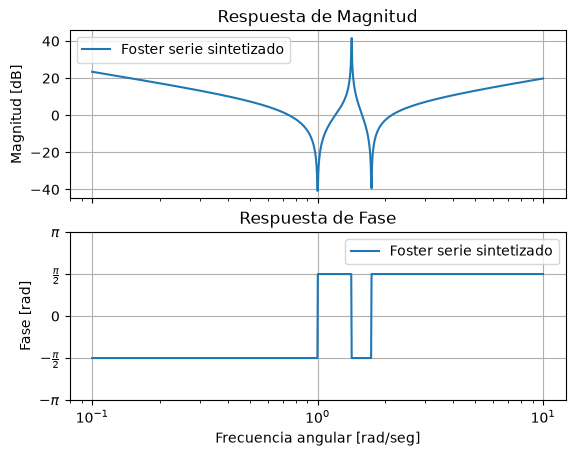

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as sig
from pytc2.sistemas_lineales import bodePlot

num, den = sp.fraction(sp.cancel(Z_foster))
num = np.array([
    float(c) for c in sp.Poly(num, s).all_coeffs()
])
den = np.array([
    float(c) for c in sp.Poly(den, s).all_coeffs()
])

Z_tf = sig.TransferFunction(num, den)

bodePlot(
    Z_tf,
    filter_description='Foster serie sintetizado'
)
plt.show()

#### Y(s) derivación

Aquí pide expresarlo en admitancias en derivación. Por lo que puedo reutilizar los coeficientes que ya calculé pero con una particularidad, que estando en admitancia cada coeficiente representa un componente nuevo:
* $\large s\cdot k_{\infty}$ es un Capacitor en derivación
* $\large \frac{k_0}{s}$ es un Inductor en derivación
* $\large \frac{2k_1\cdot s}{s^2 + w_1^2}$ es un Tanque LC en serie

<div style="text-align: center;">
  <img src="recursos/foster_derivacion.png" width="600">
</div>

Siendo:
* $\large C_{inf} = k_{\infty}$
* $\large L_0 = 1/k_0$
* $\large L = \frac{1}{2k1}$
* $\large C = \frac{2k1}{w1^2}$

Ahora lo simulo en LTSpice y grafico la corriente de entrada sobre la tensión de entrada para hallar la $Y(s)$.

##### Módulo
<div style="text-align: center;">
  <img src="recursos/foster_derivacion_spice_modulo.png" width="600">
</div>

##### Fase
<div style="text-align: center;">
  <img src="recursos/foster_derivacion_spice_fase.png" width="600">
</div>

A simple vista se pueden analizar el capacitor e inductor en alta y baja frecuencia. 

##### Tanque LC
Para ver el tanque le haré un zoom y colocaré cursores para observarlo mejor.

<div style="text-align: center;">
  <img src="recursos/foster_derivacion_spice_modulo_z1.png" width="600">
</div>

<div style="text-align: center;">
  <img src="recursos/foster_derivacion_spice_modulo_z2.png" width="600">
</div>

<div style="text-align: center;">
  <img src="recursos/foster_derivacion_spice_modulo_p1.png" width="600">
</div>

Los primeros dos gráficos hacen referencia a los ceros. 
$$f_{z1} = 159.11\ mHz \Rightarrow w_{z1} = 1$$
$$f_{z2} = 256.6\ mHz \Rightarrow w_{z2} = 1.73$$

Y la tercer imagen hace referencia al polo puesto por el tanque.
$$f_{p1} = 225.06\ mHz \Rightarrow w_{p1} = 1.41$$

Siendo que $1.41 \approx \sqrt{2}$ por lo que tiene sentido el resultado obtenido. 

##### Comprobación con Python

In [35]:

import sympy as sp
from pytc2.general import s

C_inf = sp.Integer(1)       # Capacitor en derivacion
L0 = sp.Rational(2, 3)       # Inductor en derivacion
L1 = sp.Integer(2)           # Inductor del tanque LC serie
C1 = sp.Rational(1, 4)       # Capacitor del tanque LC serie

Y_Cinf = s * C_inf
Y_L0 = 1 / (s * L0)
Z_LC = s * L1 + 1 / (s * C1)
Y_LC = 1 / Z_LC

Y_foster = sp.factor(Y_Cinf + Y_L0 + Y_LC)

Y_original = (s**4 + 4*s**2 + 3) / (s * (s**2 + 2))

print("Admitancia sintetizada:")
display(sp.factor(Y_foster))

print("¿Son equivalentes?")

if sp.simplify(Y_foster - Y_original) == 0:
    print("SI")
else:
    print("NO")

Admitancia sintetizada:


(s**2 + 1)*(s**2 + 3)/(s*(s**2 + 2))

¿Son equivalentes?
SI


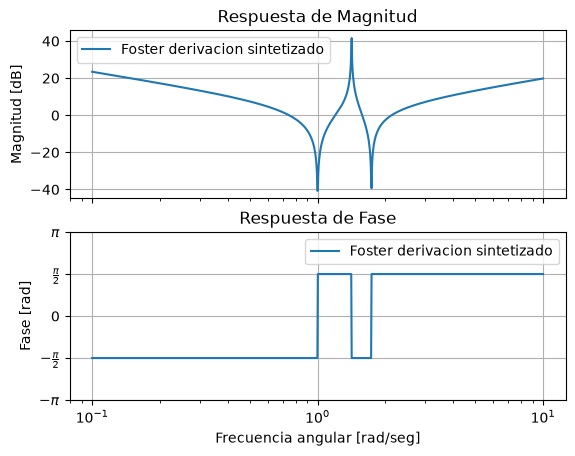

In [36]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as sig
from pytc2.sistemas_lineales import bodePlot

num, den = sp.fraction(sp.cancel(Y_foster))
num = np.array([
    float(c) for c in sp.Poly(num, s).all_coeffs()
])
den = np.array([
    float(c) for c in sp.Poly(den, s).all_coeffs()
])

Y_tf = sig.TransferFunction(num, den)
bodePlot(Y_tf, filter_description='Foster derivacion sintetizado')
plt.show()


### Cauer

Para este método se realizarán remociones. Pueden ser en el origen (DC) o en infinito. Para ello lo que haré es dividir el numerador sobre el denominador. Pero buscaré anular términos convenientemente según cada caso.

Para el caso de remoción en DC buscaré ordenar el polinomio "al revés" (de menor grado a mayor grado) para así poder sacarme primero los términos de menor grado. Esto para hallar $k_0$. 

Y para la remoción en $\infty$ haré lo opuesto, escribiendo el polinomio como estamos acostumbrados y así hallar $k_{\infty}$.

Ambos casos me darán por resultado un circuito escalera CL o LC.

Nuevamente utilizaré la inmitancia F(s).

#### Remoción en DC

Para realizar la primera extracción, divido el numerador por el denominador, ordenando los polinomios de menor a mayor grado.

<table style="border-collapse: collapse; font-family: monospace; font-size: 16px;">
  <tr>
    <td style="padding: 8px 18px; text-align: right; vertical-align: bottom;">
      $3 + 4s^2 + s^4$
    </td>
    <td style="border-left: 2px solid black; border-bottom: 2px solid black; padding: 8px 18px; text-align: center;">
      $2s + s^3$
    </td>
  </tr>
  <tr>
    <td style="padding: 8px 18px; text-align: right;">
      $3 + \frac{3}{2}s^2 + 0$
    </td>
    <td style="padding: 8px 18px; text-align: center;">
      $\frac{3}{2} \frac{1}{s}$
    </td>
  </tr>
  <tr>
    <td style="border-top: 1px solid black; padding: 8px 18px; text-align: right;">
      $\frac{5}{2}s^2 + s^4$
    </td>
    <td></td>
  </tr>
</table>

Siendo el cociente obtenido: $\frac{3}{2} \frac{1}{s}$ el equivalente a un **capacitor en serie**.
Y el resto es con lo que voy a seguir operando.

A continuación dividiré el divisor ($2s + s^3$) por el resto de la operación anterior ($\frac{5}{2}s^2 + s^4$)

<table style="border-collapse: collapse; font-family: monospace; font-size: 16px;">
  <tr>
    <td style="padding: 8px 18px; text-align: right; vertical-align: bottom;">
      $2s + s^3$
    </td>
    <td style="border-left: 2px solid black; border-bottom: 2px solid black; padding: 8px 18px; text-align: center;">
      $\frac{5}{2}s^2+s^4$
    </td>
  </tr>
  <tr>
    <td style="padding: 8px 18px; text-align: right;">
      $2s + \frac{4}{5}s^3$
    </td>
    <td style="padding: 8px 18px; text-align: center;">
      $\frac{4}{5}\frac{1}{s}$
    </td>
  </tr>
  <tr>
    <td style="border-top: 1px solid black; padding: 8px 18px; text-align: right;">
      $\frac{1}{5}s^3$
    </td>
    <td></td>
  </tr>
</table>

Siendo el cociente obtenido: $\frac{4}{5} \frac{1}{s}$ el equivalente a un **inductor en derivación**.

<table style="border-collapse: collapse; font-family: monospace; font-size: 16px;">
  <tr>
    <td style="padding: 8px 18px; text-align: right; vertical-align: bottom;">
      $\frac{5}{2}s^2 + s^4$
    </td>
    <td style="border-left: 2px solid black; border-bottom: 2px solid black; padding: 8px 18px; text-align: center;">
      $\frac{1}{5}s^3$
    </td>
  </tr>
  <tr>
    <td style="padding: 8px 18px; text-align: right;">
      $\frac{5}{2}s^2 + 0$
    </td>
    <td style="padding: 8px 18px; text-align: center;">
      $\frac{25}{2}\frac{1}{s}$
    </td>
  </tr>
  <tr>
    <td style="border-top: 1px solid black; padding: 8px 18px; text-align: right;">
      $s^4$
    </td>
    <td></td>
  </tr>
</table>

Siendo el cociente obtenido: $\frac{25}{2} \frac{1}{s}$ el equivalente a un **capacitor en serie**.

<table style="border-collapse: collapse; font-family: monospace; font-size: 16px;">
  <tr>
    <td style="padding: 8px 18px; text-align: right; vertical-align: bottom;">
      $\frac{1}{5}s^3$
    </td>
    <td style="border-left: 2px solid black; border-bottom: 2px solid black; padding: 8px 18px; text-align: center;">
      $s^4$
    </td>
  </tr>
  <tr>
    <td style="padding: 8px 18px; text-align: right;">
      $\frac{1}{5}s^3$
    </td>
    <td style="padding: 8px 18px; text-align: center;">
      $\frac{1}{5}\frac{1}{s}$
    </td>
  </tr>
  <tr>
    <td style="border-top: 1px solid black; padding: 8px 18px; text-align: right;">
      $0$
    </td>
    <td></td>
  </tr>
</table>

Siendo el último cociente obtenido: $\frac{1}{5} \frac{1}{s}$ el equivalente a un **inductor en derivación**.

Dibujando el circuito:
<div style="text-align: center;">
  <img src="recursos/cauer_dc.png" width="600">
</div>

Siendo:
* $C1 = 2/3\ F$
* $L2 = 5/4\ H$
* $C3 = 2/25\ F$
* $L4 = 5\ H$

Ahora lo simulo en LTSpice y grafico la tensión de entrada sobre la corriente de entrada para hallar la $Z(s)$.

##### Módulo
<div style="text-align: center;">
  <img src="recursos/cauer_dc_spice_modulo.png" width="600">
</div>

##### Fase
<div style="text-align: center;">
  <img src="recursos/cauer_dc_spice_fase.png" width="600">
</div>

##### Cursores
Para ver los valores numéricos de los ceros y polo colocaré cursores.

<div style="text-align: center;">
  <img src="recursos/cauer_dc_spice_modulo_z1.png" width="600">
</div>

<div style="text-align: center;">
  <img src="recursos/cauer_dc_spice_modulo_z2.png" width="600">
</div>

<div style="text-align: center;">
  <img src="recursos/cauer_dc_spice_modulo_p1.png" width="600">
</div>

Obteniendo los mismos resultados que en Foster.

##### Comprobación con Python

In [49]:

# Remoción en DC

Z_original = (s**4 + 4*s**2 + 3) / (s**3 + 2*s)

C1 = sp.Rational(2, 3)
L2 = sp.Rational(5, 4)
C3 = sp.Rational(2, 25)
L4 = sp.Integer(5)

Z_C1 = 1 / (s * C1)
Z_L2 = s * L2
Z_C3 = 1 / (s * C3)
Z_L4 = s * L4

# C3 y L4 están en serie
Z_rama = Z_C3 + Z_L4

# Esa rama está en paralelo con L2
Z_paralelo = 1 / (1 / Z_L2 + 1 / Z_rama)

# C1 está en serie con el conjunto anterior
Z_cauer_dc = sp.factor(Z_C1 + Z_paralelo)

diferencia = sp.simplify(Z_cauer_dc - Z_original)

display(sp.factor(Z_cauer_dc))
print("¿Son equivalentes?")

if diferencia == 0:
    print("SI")
else:
    print("NO")

(s**2 + 1)*(s**2 + 3)/(s*(s**2 + 2))

¿Son equivalentes?
SI


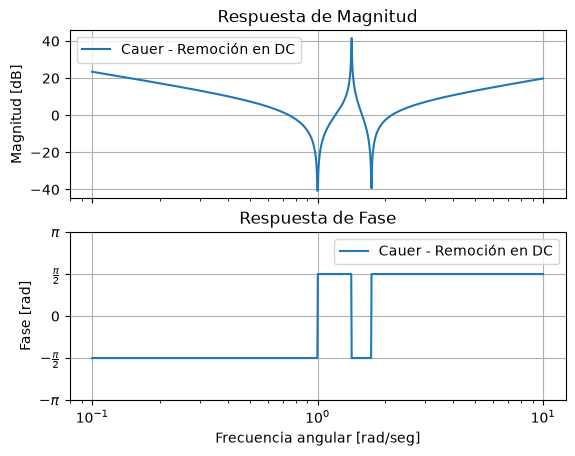

In [50]:
num, den = sp.fraction(sp.cancel(Z_cauer_dc))

num = np.array([float(c) for c in sp.Poly(num, s).all_coeffs()])
den = np.array([float(c) for c in sp.Poly(den, s).all_coeffs()])

Z_cauer_dc_tf = sig.TransferFunction(num, den)

bodePlot(
    Z_cauer_dc_tf,
    filter_description='Cauer - Remoción en DC'
)

plt.show()


#### Remoción en $\infty$

Para realizar la primera extracción, dividimos el numerador por el denominador, ordenando los polinomios de mayor a menor grado.

<table style="border-collapse: collapse; font-family: monospace; font-size: 16px;">
  <tr>
    <td style="padding: 8px 18px; text-align: right; vertical-align: bottom;">
      $s^4 + 4s^2 + 3$
    </td>
    <td style="border-left: 2px solid black; border-bottom: 2px solid black; padding: 8px 18px; text-align: center;">
      $s^3 + 2s$
    </td>
  </tr>
  <tr>
    <td style="padding: 8px 18px; text-align: right;">
      $-s^4 - 2s^2 + 0$
    </td>
    <td style="padding: 8px 18px; text-align: center;">
      $s$
    </td>
  </tr>
  <tr>
    <td style="border-top: 1px solid black; padding: 8px 18px; text-align: right;">
      $2s^2 + 3$
    </td>
    <td></td>
  </tr>
</table>

Siendo el cociente obtenido: $s$, equivalente a un inductor en serie, de valor:

$$
\boxed{L_1=1\ \mathrm{H}}
$$

El resto es con lo que voy a seguir operando.

A continuación, divido el divisor ($s^3+2s$) por el resto de la operación anterior ($2s^2+3$).

<table style="border-collapse: collapse; font-family: monospace; font-size: 16px;">
  <tr>
    <td style="padding: 8px 18px; text-align: right; vertical-align: bottom;">
      $s^3 + 2s$
    </td>
    <td style="border-left: 2px solid black; border-bottom: 2px solid black; padding: 8px 18px; text-align: center;">
      $2s^2 + 3$
    </td>
  </tr>
  <tr>
    <td style="padding: 8px 18px; text-align: right;">
      $-s^3 - \frac{3}{2}s$
    </td>
    <td style="padding: 8px 18px; text-align: center;">
      $\frac{1}{2}s$
    </td>
  </tr>
  <tr>
    <td style="border-top: 1px solid black; padding: 8px 18px; text-align: right;">
      $\frac{1}{2}s$
    </td>
    <td></td>
  </tr>
</table>

Siendo el cociente obtenido: $\frac{1}{2}s$, equivalente a la admitancia de un capacitor en derivación:

$$
Y_C(s)=sC_2
$$

Por lo tanto:

$$
\boxed{C_2=\frac{1}{2}\ \mathrm{F}}
$$

A continuación, divido el divisor ($2s^2+3$) por el resto de la operación anterior ($\frac{1}{2}s$).

<table style="border-collapse: collapse; font-family: monospace; font-size: 16px;">
  <tr>
    <td style="padding: 8px 18px; text-align: right; vertical-align: bottom;">
      $2s^2 + 3$
    </td>
    <td style="border-left: 2px solid black; border-bottom: 2px solid black; padding: 8px 18px; text-align: center;">
      $\frac{1}{2}s$
    </td>
  </tr>
  <tr>
    <td style="padding: 8px 18px; text-align: right;">
      $-2s^2 + 0$
    </td>
    <td style="padding: 8px 18px; text-align: center;">
      $4s$
    </td>
  </tr>
  <tr>
    <td style="border-top: 1px solid black; padding: 8px 18px; text-align: right;">
      $3$
    </td>
    <td></td>
  </tr>
</table>

Siendo el cociente obtenido: $4s$, equivalente a un inductor en serie, de valor:

$$
\boxed{L_3=4\ \mathrm{H}}
$$

Finalmente, divido el divisor anterior ($\frac{1}{2}s$) por el resto obtenido ($3$).

<table style="border-collapse: collapse; font-family: monospace; font-size: 16px;">
  <tr>
    <td style="padding: 8px 18px; text-align: right; vertical-align: bottom;">
      $\frac{1}{2}s$
    </td>
    <td style="border-left: 2px solid black; border-bottom: 2px solid black; padding: 8px 18px; text-align: center;">
      $3$
    </td>
  </tr>
  <tr>
    <td style="padding: 8px 18px; text-align: right;">
      $-\frac{1}{2}s$
    </td>
    <td style="padding: 8px 18px; text-align: center;">
      $\frac{1}{6}s$
    </td>
  </tr>
  <tr>
    <td style="border-top: 1px solid black; padding: 8px 18px; text-align: right;">
      $0$
    </td>
    <td></td>
  </tr>
</table>

Siendo el último cociente obtenido: $\frac{1}{6}s$, equivalente a la admitancia de un capacitor en derivación, de valor:

$$
\boxed{C_4=\frac{1}{6}\ \mathrm{F}}
$$

Ahora dibujo el circuito:

<div style="text-align: center;">
  <img src="recursos/cauer_inf.png" width="600">
</div>

Siendo:

* $L_1=1\ \mathrm{H}$
* $C_2=\frac{1}{2}\ \mathrm{F}$
* $L_3=4\ \mathrm{H}$
* $C_4=\frac{1}{6}\ \mathrm{F}$

Ahora simulo el circuito en LTspice y grafico la tensión de entrada sobre la corriente de entrada para obtener $Z(s)$.

Módulo

<div style="text-align: center;">
  <img src="recursos/cauer_inf_spice_modulo.png" width="600">
</div>

Fase

<div style="text-align: center;">
  <img src="recursos/cauer_inf_spice_fase.png" width="600">
</div>

Cursores

Para verificar los valores numéricos de los ceros y polos, colocaré cursores en las gráficas de módulo.

<div style="text-align: center;">
  <img src="recursos/cauer_inf_spice_modulo_z1.png" width="600">
</div>

<div style="text-align: center;">
  <img src="recursos/cauer_inf_spice_modulo_z2.png" width="600">
</div>

<div style="text-align: center;">
  <img src="recursos/cauer_inf_spice_modulo_p1.png" width="600">
</div>

Otra vez, obteniendo los mismos resultados que antes.

##### Comprobación con Python


In [47]:

import sympy as sp
from pytc2.general import s

# Componentes obtenidos por Cauer en infinito
L1 = sp.Integer(1)
C2 = sp.Rational(1, 2)
L3 = sp.Integer(4)
C4 = sp.Rational(1, 6)

Z_L1 = s * L1
Y_C2 = s * C2
Z_resto_1 = 1 / Y_C2
Z_resto_2 = s * L3 + 1 / (s * C4)
Z_paralelo = 1 / (Y_C2 + 1 / Z_resto_2)

Z_cauer_inf = sp.factor(Z_L1 + Z_paralelo)

Z_original = (s**4 + 4*s**2 + 3) / (s**3 + 2*s)

print("Impedancia sintetizada:")
display(sp.factor(Z_cauer_inf))

print("¿Son equivalentes?")

if sp.simplify(Z_cauer_inf - Z_original) == 0:
    print("SI")
else:
    print("NO")


Impedancia sintetizada:


(s**2 + 1)*(s**2 + 3)/(s*(s**2 + 2))

¿Son equivalentes?
SI


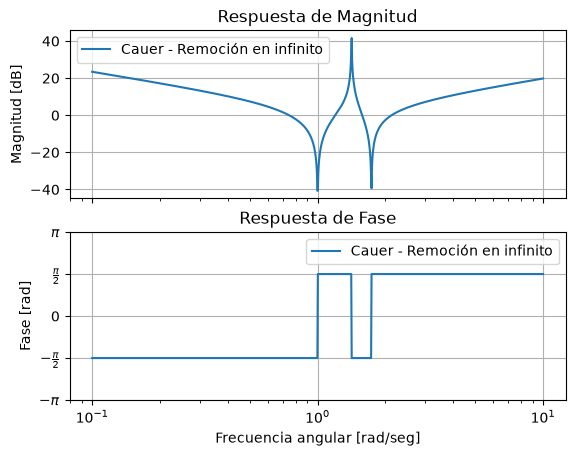

In [42]:


num, den = sp.fraction(sp.cancel(Z_cauer_inf))

num = np.array([float(c) for c in sp.Poly(num, s).all_coeffs()])
den = np.array([float(c) for c in sp.Poly(den, s).all_coeffs()])

Z_cauer_inf_tf = sig.TransferFunction(num, den)

bodePlot(
    Z_cauer_inf_tf,
    filter_description='Cauer - Remoción en infinito'
)

plt.show()


## Desde Circuito hacia valores de los componentes

Para esta segunda parte del ejercicio tengo disponible el circuito y la ecuación impedancia correspondiente.

$$Y(s) = \frac{s^5 + 18s^3 +48s}{6s^4 + 42s^2 + 48}$$

Y el circuito:

<div style="text-align: center;">
  <img src="recursos/circuito_2.png" width="500">
</div>

En base a esto obtendré los valores de cada componente haciendo remociones y esquematizándolas con un gráfico.

A partir de la función admitancia propuesta, se determinarán los valores de los componentes mediante el método de remoción de polos y ceros. Para ello, se analizará la función por etapas, identificando las contribuciones de cada componente y representando gráficamente las remociones realizadas.

### Primera remoción: capacitor C1

Partimos de la función admitancia del circuito:

$$
Y(s)=\frac{s^5+18s^3+48s}{6s^4+42s^2+48}
$$

Para aplicar el método de remoción, trabajo con la función impedancia correspondiente:

$$
Z(s)=\frac{1}{Y(s)}
$$

Por lo tanto,

$$
Z(s)=\frac{6s^4+42s^2+48}{s^5+18s^3+48s}
$$

Como el primer componente del circuito es el capacitor $C_1$, conectado en serie, su impedancia es:

$$
Z_{C_1}(s)=\frac{1}{sC_1}
$$

El valor de $C_1$ se obtiene a partir del residuo de $Z(s)$ en el origen:

$$
\frac{1}{C_1}=\lim_{s\to 0}sZ(s)
$$

Reemplazando la función impedancia:

$$\frac{1}{C_1}=
\lim_{s\to 0}
\frac{6s^4+42s^2+48}{s^4+18s^2+48}
=1
$$

En consecuencia,

$$
\boxed{C_1=1\ \mathrm{F}}
$$

Una vez determinado el componente, lo resto:

$$
Z_2(s)=Z(s)-\frac{1}{sC_1}
$$

Como $C_1=1\ \mathrm{F}$,

$$
Z_2(s)=
\frac{6s^4+42s^2+48}{s^5+18s^3+48s}
-\frac{1}{s}
$$

Operando y simplificando:

$$
Z_2(s)=
\frac{5s^4+24s^2}{s^5+18s^3+48s}
$$

Cancelando el factor común $s$, obtengo la función sin ese componente:

$$
\boxed{
Z_2(s)=\frac{5s^3+24s}{s^4+18s^2+48}
}
$$

Esta función representa la impedancia del circuito restante luego de remover el capacitor $C_1$.

### Segunda remoción: inductor $L_1$

Luego de obtener el valor de $C_1$ y removerlo, trabajo con la función impedancia residual:

$$
Z_2(s)=\frac{5s^3+24s}{s^4+18s^2+48}
$$

Para continuar con el método de remoción, trabajo con la función admitancia correspondiente:

$$
Y_2(s)=\frac{1}{Z_2(s)}
=\frac{s^4+18s^2+48}{5s^3+24s}
$$

Como el siguiente componente es el inductor $L_1$, conectado en derivación, su admitancia está dada por:

$$
Y_{L_1}(s)=\frac{1}{sL_1}
$$

Para calcular su valor, utilizo el residuo de la función admitancia en el origen:

$$
\frac{1}{L_1}=\lim_{s\to 0}sY_2(s)
$$

Reemplazando la función obtenida:

$$
\frac{1}{L_1}
=\lim_{s\to 0}
\frac{s^4+18s^2+48}{5s^2+24}
=\frac{48}{24}=2
$$

Por lo tanto, obtengo:

$$
\boxed{L_1=\frac{1}{2}\ \mathrm{H}}
$$

Una vez calculado el inductor, lo remuevo de la función admitancia mediante una resta:

$$
Y_4(s)=Y_2(s)-\frac{1}{sL_1}
$$

Reemplazando el valor obtenido:

$$
Y_4(s)=
\frac{s^4+18s^2+48}{5s^3+24s}
-\frac{2}{s}
$$

Operando y simplificando:

$$
Y_4(s)=
\frac{s^4+18s^2+48-2(5s^2+24)}
{5s^3+24s}
$$

$$
Y_4(s)=
\frac{s^4+8s^2}{5s^3+24s}
$$

Finalmente, factorizo y simplifico el factor común $s$:

$$
Y_4(s)=
\frac{s^2(s^2+8)}{s(5s^2+24)}
$$

$$
\boxed{
Y_4(s)=\frac{s(s^2+8)}{5s^2+24}
}
$$

Esta es la función admitancia residual que utilizo para continuar con la siguiente remoción.

### Tercera remoción: tanque LC

Partiendo de la función admitancia obtenida en la remoción anterior, tengo:

$$
\boxed{
Y_4(s)=\frac{s(s^2+8)}{5s^2+24}
}
$$

Para continuar con el método de remoción, trabajo con la función impedancia correspondiente:

$$
Z_4(s)=\frac{1}{Y_4(s)}
=\frac{5s^2+24}{s(s^2+8)}
$$

Por inspección del denominador de $Z_4(s)$, identifico un tanque LC asociado al término $s^2+8$. Por lo tanto, la frecuencia angular de resonancia cumple:

$$
\omega_1^2=8
$$

$$
\boxed{\omega_1=\sqrt{8}\ \mathrm{rad/s}}
$$

Para obtener la impedancia del tanque LC, busco el residuo $k1$.

$$2k1
=\lim_{s^2\to (-8)}
\frac{s^2 + 8}{s} \frac{5s^2 + 24}{s(s^2 + 8)}=2$$

Expresándolo de la manera genérica de un tanque en impedancia:
$$Z_5(s) = \frac{2k1\cdot s}{s^2 + 8}$$

$$Z_5(s) = \frac{2 s}{s^2 + 8}$$

Obtengo las siguientes relaciones:

$$
\frac{1}{C_2}=2
$$

$$
\frac{1}{L_2C_2}=8
$$

De la primera ecuación obtengo:

$$
\boxed{C_2=\frac{1}{2}\ \mathrm{F}}
$$

Reemplazando este valor en la segunda ecuación:

$$
\frac{1}{L_2\cdot\frac{1}{2}}=8
$$

$$
\frac{2}{L_2}=8
$$

Por lo tanto, el valor del inductor es:

$$
\boxed{L_2=\frac{1}{4}\ \mathrm{H}}
$$

Una vez obtenido el tanque LC, lo remuevo de la función impedancia original para determinar la función residual:

$$
Z_6(s)=Z_4(s)-Z_5(s)
$$

Reemplazando las expresiones correspondientes:

$$
Z_6(s)=
\frac{5s^2+24}{s(s^2+8)}
-\frac{2s}{s^2+8}
$$

Operando:

$$
Z_6(s)=
\frac{5s^2+24-2s^2}{s(s^2+8)}
$$

$$
Z_6(s)=
\frac{3s^2+24}{s(s^2+8)}
$$

Factorizando el numerador:

$$
Z_6(s)=
\frac{3(s^2+8)}{s(s^2+8)}
$$

Finalmente, simplificando, obtengo:

$$
\boxed{
Z_6(s)=\frac{3}{s}
}
$$

A partir de la función impedancia residual obtenida, identifico que corresponde a la impedancia de un capacitor, cuya expresión es:

$$
Z_C(s)=\frac{1}{sC}
$$

Comparando con la función obtenida:

$$
Z_6(s)=\frac{3}{s}
$$

Obtengo la siguiente relación:

$$
\frac{1}{C_4}=3
$$

Por lo tanto, el valor del capacitor es:

$$
\boxed{C_4=\frac{1}{3}\ \mathrm{F}}
$$

De esta manera, finalizo el proceso de remoción, obteniendo los valores de los componentes del circuito a partir de la función admitancia inicial.

### Simulación en LTSpice

Ahora puedo simular el circuito en LTSpice con valores.

<div style="text-align: center;">
  <img src="recursos/circuito_2_valores.png" width="500">
</div>

Simularé módulo y fase haciendo $V(in)/I(in)$ por lo que obtendré una impedancia $Z(s)$.

#### Módulo
<div style="text-align: center;">
  <img src="recursos/circuito_2_modulo.png" width="500">
</div>

#### Fase
<div style="text-align: center;">
  <img src="recursos/circuito_2_fase.png" width="500">
</div>

Mediante el análisis de cursores se obtienen los valores de los polos y ceros intermedios
* $z_1 = 190.89mHz \Rightarrow z_1 = 1.2\ rad/s$
* $p_1 = 287.14mHz \Rightarrow p_1 = 1.8\ rad/s$
* $z_2 = 375.31mHz \Rightarrow z_2 = 2.36\ rad/s$
* $p_2 = 611.08mHz \Rightarrow p_2 = 3.84\ rad/s$

Además se ve que tengo un polo en el origen y por alternancia un cero en el infinito.

### Método gráfico

Para el método gráfico se adjunta el método resuelto partiendo de los valores conocidos y llegando hasta la última remoción:

<div style="text-align: center;">
  <img src="recursos/circuito_2_metodo_grafico.png" width="500">
</div>